# Waveform + recursive STA/LTA for a single `.mseed` file

Set the parameters in the second cell, then run all cells.
Requires `obspy`, `numpy`, `matplotlib`.

In [5]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
from obspy import UTCDateTime, read
from obspy.signal.trigger import recursive_sta_lta, trigger_onset

plt.rcParams["agg.path.chunksize"] = 10000  # keeps long traces fast to draw

## Parameters

In [6]:
FILE    = "year_Virgo_data/2022/VRG01_HH3_2022-01-15.mseed"
CHANNEL = "HH3"      # e.g. "HH1" if the file contains several channels

# Recursive STA/LTA
STA     = 0.5       # short window (s)
LTA     = 60.0      # long window (s)
THR_ON  = 20.0
THR_OFF = 1.5

# Optional filter applied before STA/LTA (Hz). Both -> band-pass, one -> high/low-pass
FMIN    = 2
FMAX    = 30

# Optional zoom for the figure (UTC, ISO format), e.g. "2019-12-02T10:15:00"
START   = None
END     = None

SAVE_AS = "AA"      # e.g. "stalta.png"; None -> <file>_stalta.png
DPI     = 300

## Load

In [7]:
st = read(FILE)
if CHANNEL:
    st = st.select(channel=CHANNEL)
assert len(st) > 0, "No traces found (check CHANNEL)."

# Join segments of the same id; small gaps are interpolated
st.merge(method=1, fill_value="interpolate")
if len(st) > 1:
    print(f"File has {len(st)} traces, using the first one: {[t.id for t in st]}. Set CHANNEL to pick another.")

st[0].stats

         network: VR
         station: VRG01
        location: 
         channel: HH3
       starttime: 2022-01-15T00:00:00.000000Z
         endtime: 2022-01-16T00:00:00.560000Z
   sampling_rate: 100.0
           delta: 0.01
            npts: 8640057
           calib: 1.0
         _format: MSEED
           mseed: AttribDict({'dataquality': 'D', 'number_of_records': 172801, 'encoding': 'FLOAT64', 'byteorder': '>', 'record_length': 512, 'filesize': 1048576})

## Pre-processing and recursive STA/LTA

In [8]:
tr = st[0].copy()          # copy, so re-running this cell never filters twice
fs = tr.stats.sampling_rate
print(f"{tr.id} | {tr.stats.starttime} -> {tr.stats.endtime} | {fs:g} Hz | {tr.stats.npts} samples")

tr.detrend("demean")
if FMIN and FMAX:
    tr.filter("bandpass", freqmin=FMIN, freqmax=FMAX, corners=4, zerophase=True)
elif FMIN:
    tr.filter("highpass", freq=FMIN, corners=4, zerophase=True)
elif FMAX:
    tr.filter("lowpass", freq=FMAX, corners=4, zerophase=True)

nsta = int(round(STA * fs))
nlta = int(round(LTA * fs))
assert nlta < tr.stats.npts, "LTA window is longer than the trace."

cft = recursive_sta_lta(tr.data.astype(np.float64), nsta, nlta)
cft[:nlta] = 0.0           # discard the start-up transient of the LTA
onsets = trigger_onset(cft, THR_ON, THR_OFF)
print(f"{len(onsets)} trigger(s) with THR_ON={THR_ON}, THR_OFF={THR_OFF}")

VR.VRG01..HH3 | 2022-01-15T00:00:00.000000Z -> 2022-01-16T00:00:00.560000Z | 100 Hz | 8640057 samples
11 trigger(s) with THR_ON=20.0, THR_OFF=1.5


## Plot

Saved: AA


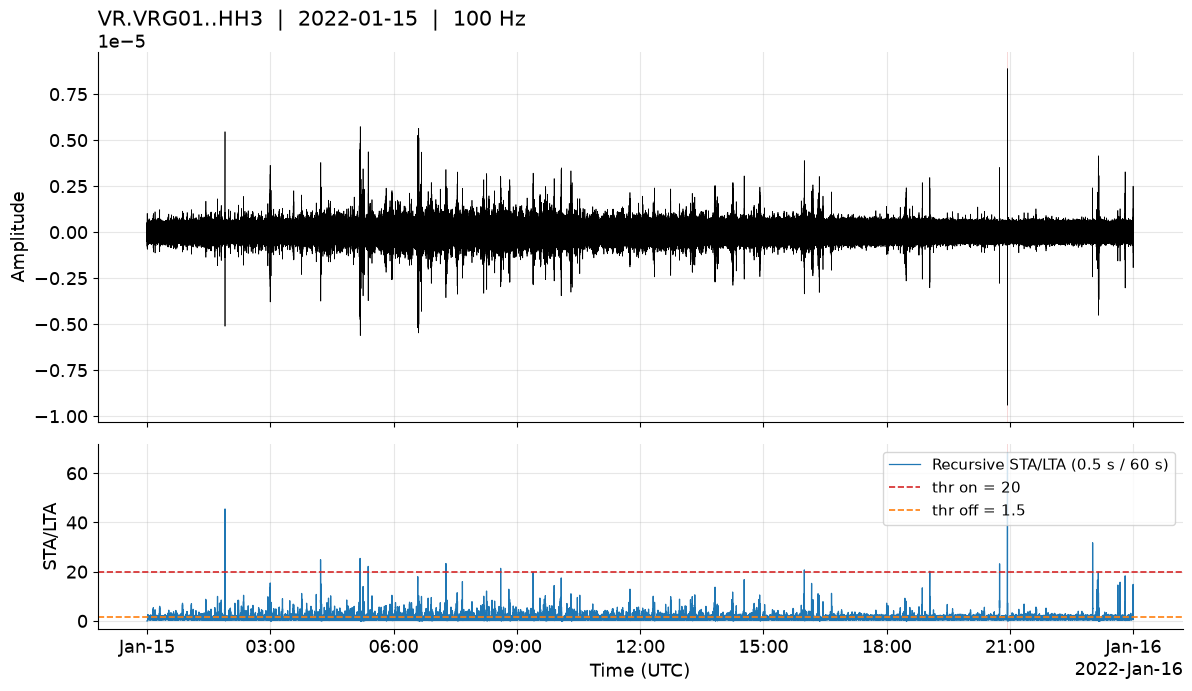

In [9]:
t = tr.times("matplotlib")

plt.rcParams.update({"font.size": 13, "axes.titlesize": 15, "axes.labelsize": 13})
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1], "hspace": 0.08})

ax1.plot(t, tr.data, color="black", lw=0.5)
ax1.set_ylabel("Amplitude")
ax1.set_title(f"{tr.id}  |  {tr.stats.starttime.date}  |  {fs:g} Hz", loc="left")

ax2.plot(t, cft, color="tab:blue", lw=0.9, label=f"Recursive STA/LTA ({STA:g} s / {LTA:g} s)")
ax2.axhline(THR_ON, color="tab:red", ls="--", lw=1.2, label=f"thr on = {THR_ON:g}")
ax2.axhline(THR_OFF, color="tab:orange", ls="--", lw=1.2, label=f"thr off = {THR_OFF:g}")
ax2.set_ylabel("STA/LTA")
ax2.set_xlabel("Time (UTC)")
ax2.legend(loc="upper right", frameon=True, fontsize=11)

for on, off in onsets:
    off = min(off, len(t) - 1)
    for ax in (ax1, ax2):
        ax.axvspan(t[on], t[off], color="tab:red", alpha=0.18, lw=0)

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

locator = mdates.AutoDateLocator()
ax2.xaxis.set_major_locator(locator)
ax2.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

# Optional zoom (STA/LTA was computed on the full trace, so no warm-up artefact)
if START or END:
    t0 = UTCDateTime(START) if START else tr.stats.starttime
    t1 = UTCDateTime(END) if END else tr.stats.endtime
    ax1.set_xlim(t0.matplotlib_date, t1.matplotlib_date)
    i0 = max(int((t0 - tr.stats.starttime) * fs), 0)
    i1 = min(int((t1 - tr.stats.starttime) * fs), tr.stats.npts)
    seg, cseg = tr.data[i0:i1], cft[i0:i1]
    if len(seg):
        pad = 0.05 * (seg.max() - seg.min() or 1.0)
        ax1.set_ylim(seg.min() - pad, seg.max() + pad)
        ax2.set_ylim(0, max(cseg.max() * 1.1, THR_ON * 1.2))

out = SAVE_AS or str(Path(FILE).with_suffix("")) + "_stalta.png"
fig.savefig(out, dpi=DPI, bbox_inches="tight")
print(f"Saved: {out}")
plt.show()